
# Customer Segmentation Analysis Using K-Means Clustering

## Objective
The objective of this project is to segment an e-commerce company's customers based on purchasing behavior using K-Means clustering and RFM (Recency, Frequency, Monetary) analysis.

## Project Goals
- Inspect and clean the retail transaction dataset.
- Calculate customer purchasing statistics.
- Create Recency, Frequency, and Monetary features.
- Standardize features using StandardScaler.
- Determine the optimal number of clusters using the Elbow Method.
- Apply K-Means clustering.
- Visualize and profile customer segments.
- Recommend targeted marketing strategies for each segment.

## Technologies Used
Python, Pandas, NumPy, Scikit-learn, Matplotlib, Seaborn, and Jupyter Notebook.


In [4]:
%pip install openpyxl

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.titlesize"] = 15

df = pd.read_excel("Online Retail.xlsx")

print("CUSTOMER SEGMENTATION DATASET LOADED")
print("=" * 45)
print("Dataset shape:", df.shape)
display(df.head())

CUSTOMER SEGMENTATION DATASET LOADED
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## 1. Data Inspection and Cleaning

In this section, the Online Retail dataset is inspected to understand its structure, data types, missing values, and duplicate records. Inconsistent transactions, missing customer identifiers, and invalid quantity or price values are examined to prepare reliable data for customer segmentation.


In [6]:

print("Dataset Shape:", df.shape)

print("\nColumn Names and Data Types:")
display(df.dtypes.to_frame(name="Data Type"))

print("\nMissing Values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe(include="all").T)

print("\nFirst 5 Rows:")
display(df.head())


Dataset Shape: (541909, 8)

Column Names and Data Types:


,Data Type
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object



Missing Values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate Rows: 5268

Descriptive Statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN



First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom



## 2. Data Cleaning and Preprocessing

The dataset is cleaned to improve the reliability of customer segmentation. Missing customer IDs are removed because customer-level analysis requires identifying individual customers. Duplicate transactions are removed, and invalid records with non-positive quantities or unit prices are excluded. Transaction dates are converted to datetime format for accurate analysis.


In [7]:

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

print("Rows before cleaning:", len(df))

df = df.dropna(subset=["CustomerID", "InvoiceDate", "Quantity", "UnitPrice"])
df = df.drop_duplicates()
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]
df = df[df["InvoiceNo"].astype(str).str.startswith("C") == False]

df["CustomerID"] = df["CustomerID"].astype(int)
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print("Rows after cleaning:", len(df))
print("Unique customers:", df["CustomerID"].nunique())
print("Missing values after cleaning:")
display(df.isnull().sum().to_frame(name="Missing Values"))
print("Cleaned dataset preview:")
display(df.head())


Rows before cleaning: 541909
Rows after cleaning: 392692
Unique customers: 4338
Missing values after cleaning:


,Missing Values
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0
TotalPrice,0


Cleaned dataset preview:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34



## Descriptive Statistics of Customer Purchasing Behaviour

Descriptive statistics are calculated to understand customer purchasing behaviour. The analysis examines average purchase value, purchase frequency, and customer lifetime value using transaction data. These metrics provide an overview of customer spending patterns and purchasing activity.


In [8]:

customer_stats = df.groupby("CustomerID").agg(
    Total_Purchases=("InvoiceNo", "nunique"),
    Total_Quantity=("Quantity", "sum"),
    Total_Spending=("TotalPrice", "sum"),
    First_Purchase=("InvoiceDate", "min"),
    Last_Purchase=("InvoiceDate", "max")
)

customer_stats["Average_Purchase_Value"] = (
    customer_stats["Total_Spending"] / customer_stats["Total_Purchases"]
)

customer_stats["Customer_Lifetime_Days"] = (
    customer_stats["Last_Purchase"] - customer_stats["First_Purchase"]
).dt.days

print("Customer-Level Statistics:")
display(customer_stats.head())

print("\nSummary of Customer Purchasing Behaviour:")
display(customer_stats[[
    "Total_Purchases",
    "Total_Quantity",
    "Total_Spending",
    "Average_Purchase_Value",
    "Customer_Lifetime_Days"
]].describe().round(2))

print("\nAverage Purchase Value:", round(customer_stats["Average_Purchase_Value"].mean(), 2))
print("Average Purchase Frequency:", round(customer_stats["Total_Purchases"].mean(), 2))
print("Average Customer Spending:", round(customer_stats["Total_Spending"].mean(), 2))


Customer-Level Statistics:


,Total_Purchases,Total_Quantity,Total_Spending,First_Purchase,Last_Purchase,Average_Purchase_Value,Customer_Lifetime_Days
CustomerID,,,,,,,
12346,1,74215,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000,0
12347,7,2458,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00,615.714286,365
12348,4,2341,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00,449.310000,282
12349,1,631,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00,1757.550000,0
12350,1,197,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00,334.400000,0



Summary of Customer Purchasing Behaviour:


,Total_Purchases,Total_Quantity,Total_Spending,Average_Purchase_Value,Customer_Lifetime_Days
count,4338.00,4338.00,4338.00,4338.00,4338.00
mean,4.27,1187.64,2048.69,417.65,130.45
std,7.70,5043.62,8985.23,1796.51,132.04
min,1.00,1.00,3.75,3.45,0.00
25%,1.00,159.00,306.48,177.87,0.00
50%,2.00,378.00,668.57,291.94,92.50
75%,5.00,989.75,1660.60,428.28,251.75
max,209.00,196915.00,280206.02,84236.25,373.00



Average Purchase Value: 417.65
Average Purchase Frequency: 4.27
Average Customer Spending: 2048.69



## 4. RFM Analysis and Feature Selection

RFM analysis is a customer segmentation technique based on three key purchasing behaviours:

- **Recency:** The number of days since a customer's most recent purchase. Lower values indicate more recent activity.
- **Frequency:** The number of distinct invoices or purchases made by a customer. Higher values indicate more frequent purchases.
- **Monetary:** The total amount spent by a customer. Higher values indicate greater spending.

These three features are used to represent customer behaviour and prepare the data for K-Means clustering.


In [9]:

snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalPrice", "sum")
)

print("RFM Dataset Preview:")
display(rfm.head())

print("\nRFM Summary Statistics:")
display(rfm.describe().round(2))

print("\nNumber of Customers:", len(rfm))
print("\nMissing Values in RFM:")
display(rfm.isnull().sum().to_frame(name="Missing Values"))


RFM Dataset Preview:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40



RFM Summary Statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02



Number of Customers: 4338

Missing Values in RFM:


,Missing Values
Recency,0
Frequency,0
Monetary,0



## 5. Data Standardization for K-Means Clustering

K-Means clustering uses distances between data points to form customer groups. Since Recency, Frequency, and Monetary have different scales, the features are standardized using StandardScaler before clustering. This prevents variables with larger numerical values from dominating the clustering process.


In [10]:

rfm_model = rfm[["Recency", "Frequency", "Monetary"]].copy()

rfm_model = rfm_model.replace([np.inf, -np.inf], np.nan).dropna()

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_model)

rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=["Recency", "Frequency", "Monetary"],
    index=rfm_model.index
)

print("Original RFM Features:")
display(rfm_model.head())

print("\nStandardized RFM Features:")
display(rfm_scaled_df.head())

print("\nStandardized Feature Means:")
display(rfm_scaled_df.mean().round(4).to_frame(name="Mean"))

print("\nStandardized Feature Standard Deviations:")
display(rfm_scaled_df.std().round(4).to_frame(name="Standard Deviation"))

print("\nCustomers included in clustering:", len(rfm_scaled_df))


Original RFM Features:


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40



Standardized RFM Features:


,Recency,Frequency,Monetary
CustomerID,,,
12346,2.334574,-0.425097,8.363010
12347,-0.905340,0.354417,0.251699
12348,-0.175360,-0.035340,-0.027988
12349,-0.735345,-0.425097,-0.032406
12350,2.174578,-0.425097,-0.190812



Standardized Feature Means:


,Mean
Recency,0.0
Frequency,0.0
Monetary,0.0



Standardized Feature Standard Deviations:


,Standard Deviation
Recency,1.0001
Frequency,1.0001
Monetary,1.0001



Customers included in clustering: 4338



## 6. Determine the Optimal Number of Clusters Using the Elbow Method

The Elbow Method is used to determine a suitable number of customer clusters for K-Means. The algorithm is fitted with different values of K, and the Within-Cluster Sum of Squares (WCSS), represented by inertia, is recorded for each value.

The inertia values are plotted against the number of clusters. The point where the reduction in inertia begins to slow down, forming an elbow, helps identify a suitable number of clusters.


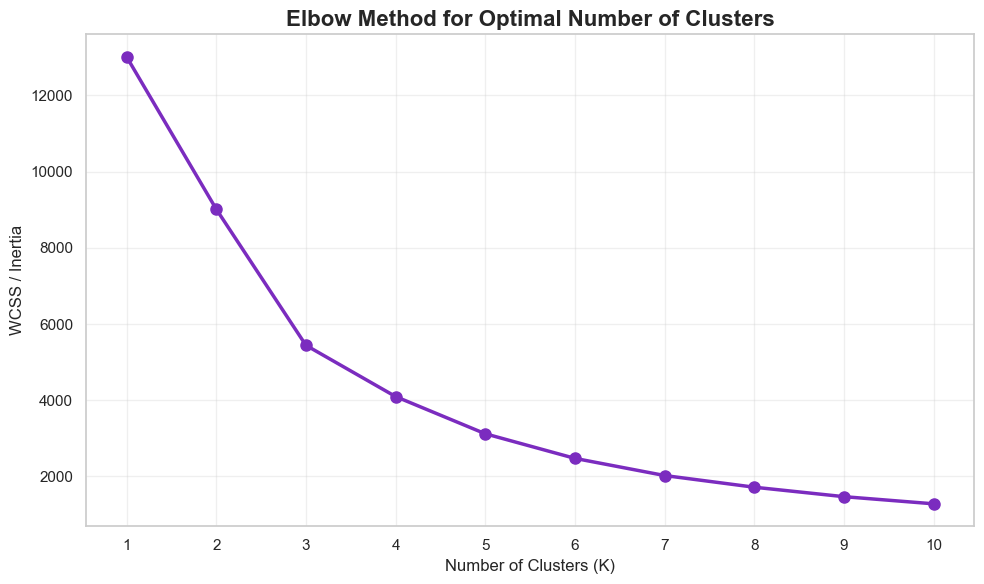

,Number of Clusters (K),Inertia
0,1,13014.00
1,2,9014.57
2,3,5441.32
3,4,4096.30
4,5,3119.79
5,6,2473.79
6,7,2023.59
7,8,1717.01
8,9,1468.79
9,10,1281.05


In [11]:

inertia_values = []

k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled_df)
    inertia_values.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(
    k_values,
    inertia_values,
    marker="o",
    linewidth=2.5,
    markersize=8,
    color="#7B2CBF"
)
plt.title("Elbow Method for Optimal Number of Clusters", fontsize=16, fontweight="bold")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Number of Clusters (K)": list(k_values),
    "Inertia": inertia_values
}).round(2))



## 7. Customer Segmentation Using K-Means Clustering

K-Means clustering is applied to group customers with similar purchasing behaviours based on their Recency, Frequency, and Monetary values. The number of clusters is selected based on the Elbow Method.

Each customer is assigned a cluster label, allowing the business to identify distinct customer segments and develop targeted marketing strategies.


In [12]:

optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

rfm_scaled_df["Cluster"] = kmeans.fit_predict(rfm_scaled_df)

rfm["Cluster"] = rfm_scaled_df["Cluster"]

print("K-Means clustering completed successfully.")
print("Number of clusters:", optimal_k)
print("\nCustomers in each cluster:")
display(rfm["Cluster"].value_counts().sort_index().to_frame(name="Customer Count"))

print("\nSample customer segments:")
display(rfm.head(10))

print("\nSilhouette Score:", round(
    silhouette_score(
        rfm_scaled_df[["Recency", "Frequency", "Monetary"]],
        rfm_scaled_df["Cluster"]
    ), 3
))


K-Means clustering completed successfully.
Number of clusters: 4

Customers in each cluster:


,Customer Count
Cluster,
0,3054
1,1067
2,13
3,204



Sample customer segments:


,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346,326,1,77183.60,3
12347,2,7,4310.00,0
12348,75,4,1797.24,0
12349,19,1,1757.55,0
12350,310,1,334.40,1
12352,36,8,2506.04,0
12353,204,1,89.00,1
12354,232,1,1079.40,1
12355,214,1,459.40,1



Silhouette Score: 0.616



## 8. Customer Cluster Visualization

The customer segments are visualized using scatter plots to examine how customers are distributed across different clusters. Two combinations of RFM features are used: Recency versus Frequency and Frequency versus Monetary.

Each cluster is represented by a different color. These visualizations help reveal similarities, differences, and patterns in customer purchasing behaviour.


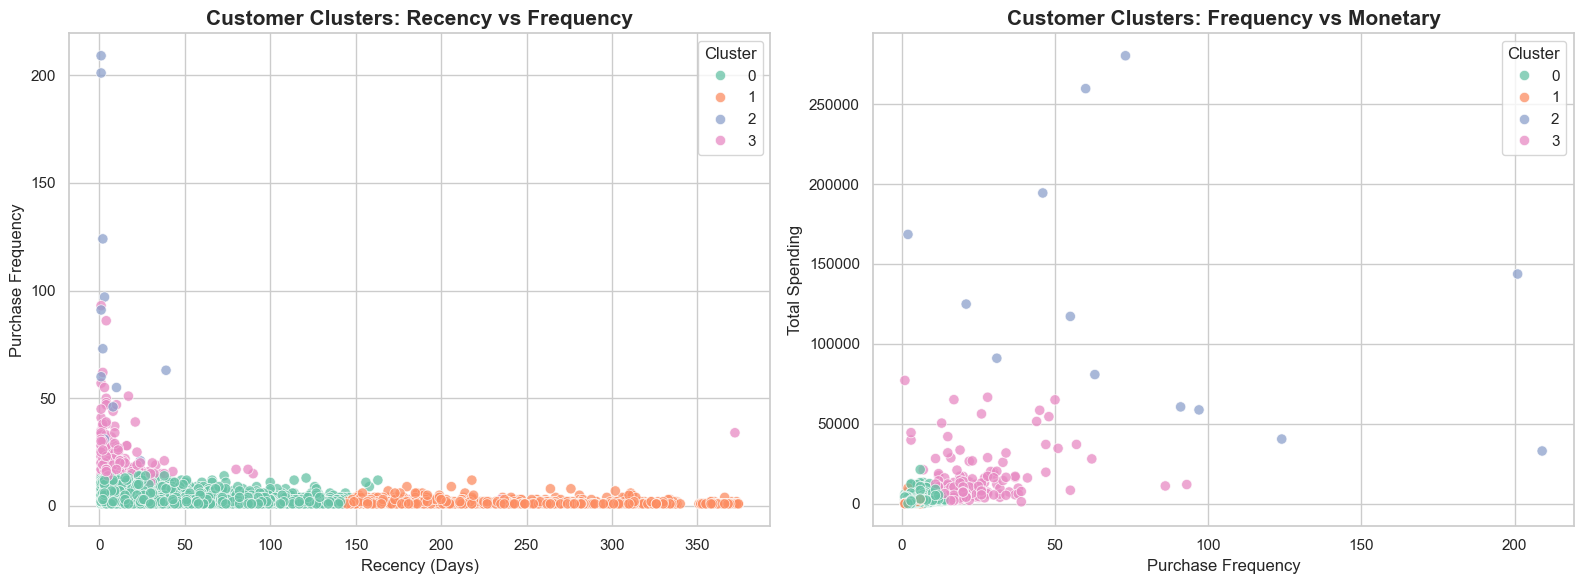

In [13]:

cluster_colors = sns.color_palette("Set2", optimal_k)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Frequency",
    hue="Cluster",
    palette=cluster_colors,
    s=55,
    alpha=0.75,
    ax=axes[0]
)
axes[0].set_title("Customer Clusters: Recency vs Frequency")
axes[0].set_xlabel("Recency (Days)")
axes[0].set_ylabel("Purchase Frequency")

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette=cluster_colors,
    s=55,
    alpha=0.75,
    ax=axes[1]
)
axes[1].set_title("Customer Clusters: Frequency vs Monetary")
axes[1].set_xlabel("Purchase Frequency")
axes[1].set_ylabel("Total Spending")

axes[0].legend(title="Cluster")
axes[1].legend(title="Cluster")
plt.tight_layout()
plt.show()



## 9. Customer Segment Profiling

Customer segment profiling summarizes the average Recency, Frequency, and Monetary values for each cluster. These measurements help identify the purchasing behaviour of each customer group and assign meaningful segment descriptions.

The results can help the business distinguish loyal customers, high-value customers, occasional buyers, and customers who may need re-engagement.


In [14]:

cluster_profile = rfm.groupby("Cluster").agg(
    Customer_Count=("Recency", "size"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
).round(2)

cluster_profile["Customer_Percentage"] = (
    cluster_profile["Customer_Count"] / len(rfm) * 100
).round(2)

print("Customer Cluster Profiles:")
display(cluster_profile)

print("\nCluster Characteristics:")

for cluster_id, row in cluster_profile.iterrows():
    print(f"\nCluster {cluster_id}")
    print(f"Customers: {int(row['Customer_Count'])} ({row['Customer_Percentage']}%)")
    print(f"Average Recency: {row['Average_Recency']:.1f} days")
    print(f"Average Frequency: {row['Average_Frequency']:.2f} purchases")
    print(f"Average Monetary: {row['Average_Monetary']:.2f}")
    print(f"Total Revenue: {row['Total_Revenue']:.2f}")


Customer Cluster Profiles:


,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue,Customer_Percentage
Cluster,,,,,,
0,3054,43.70,3.68,1353.63,4133971.70,70.4
1,1067,248.08,1.55,478.85,510931.64,24.6
2,13,7.38,82.54,127187.96,1653443.47,0.3
3,204,15.50,22.33,12690.50,2588862.08,4.7



Cluster Characteristics:

Cluster 0
Customers: 3054 (70.4%)
Average Recency: 43.7 days
Average Frequency: 3.68 purchases
Average Monetary: 1353.63
Total Revenue: 4133971.70

Cluster 1
Customers: 1067 (24.6%)
Average Recency: 248.1 days
Average Frequency: 1.55 purchases
Average Monetary: 478.85
Total Revenue: 510931.64

Cluster 2
Customers: 13 (0.3%)
Average Recency: 7.4 days
Average Frequency: 82.54 purchases
Average Monetary: 127187.96
Total Revenue: 1653443.47

Cluster 3
Customers: 204 (4.7%)
Average Recency: 15.5 days
Average Frequency: 22.33 purchases
Average Monetary: 12690.50
Total Revenue: 2588862.08



## 10. Customer Distribution Across Clusters

This section examines the number of customers assigned to each K-Means cluster. A bar chart is used to compare cluster sizes and identify which customer segments represent the largest and smallest portions of the customer base.

Understanding segment sizes helps the business allocate marketing resources effectively and decide whether to prioritize large customer groups or smaller, high-value segments.


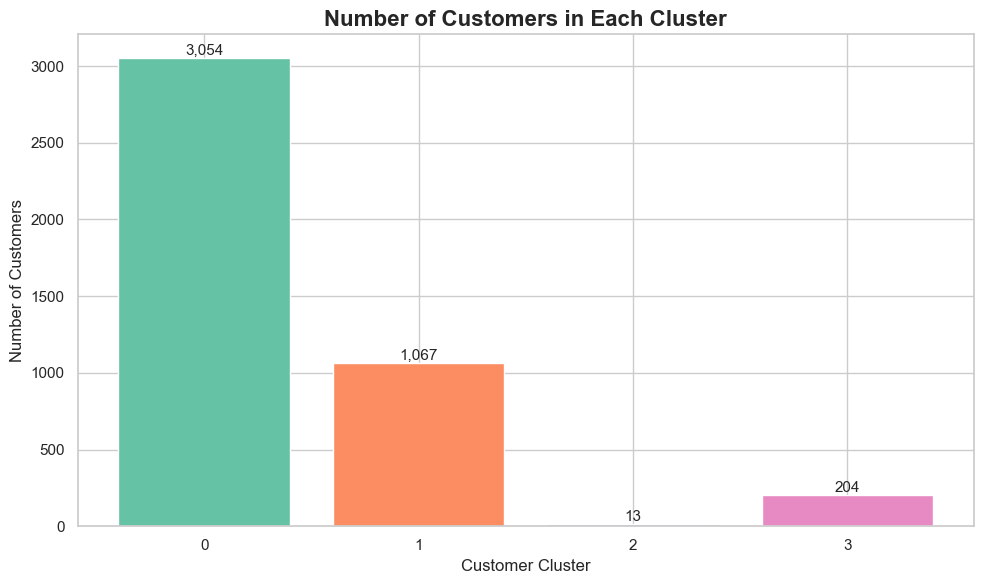

Customer distribution by cluster:


,Customer Count
Cluster,
0,3054
1,1067
2,13
3,204


Largest cluster: 0
Smallest cluster: 2


In [15]:

cluster_counts = rfm["Cluster"].value_counts().sort_index()

plt.figure(figsize=(10, 6))
bars = plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values,
    color=sns.color_palette("Set2", len(cluster_counts))
)

plt.title("Number of Customers in Each Cluster", fontsize=16, fontweight="bold")
plt.xlabel("Customer Cluster")
plt.ylabel("Number of Customers")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.tight_layout()
plt.show()

print("Customer distribution by cluster:")
display(cluster_counts.rename("Customer Count").to_frame())

print("Largest cluster:", cluster_counts.idxmax())
print("Smallest cluster:", cluster_counts.idxmin())



## 11. Customer Segmentation Insights and Marketing Recommendations

### Customer Segment Analysis

The K-Means model groups customers according to their Recency, Frequency, and Monetary (RFM) values. Each cluster represents a different purchasing behaviour pattern. The cluster profiles are used to identify suitable marketing strategies for each segment.

### Marketing Recommendations

1. **High-Value Loyal Customers:** Customers with low recency, high purchase frequency, and high spending should receive loyalty rewards, exclusive offers, early access to new products, and personalized services.

2. **Recent or Potential Loyal Customers:** Customers who have purchased recently but have moderate purchase frequency can be encouraged to purchase more often through personalized recommendations, loyalty points, and repeat-purchase discounts.

3. **Occasional Customers:** Customers with low purchase frequency can be targeted with product recommendations, bundle offers, and promotional campaigns to encourage repeat purchases.

4. **At-Risk Customers:** Customers with high recency values may not have purchased recently. Re-engagement emails, special discounts, and reminders about relevant products can encourage them to return.

5. **High-Spending Customers:** Customers with high monetary values should receive personalized offers, premium customer support, and exclusive benefits to strengthen retention.

### Important Note

These segment descriptions are general interpretations of RFM behaviour. The actual characteristics of each cluster should be confirmed using the cluster profile table before assigning a segment name or choosing a marketing strategy.

## 12. Conclusion

This project applied K-Means clustering to segment e-commerce customers using Recency, Frequency, and Monetary analysis. The dataset was inspected and cleaned, customer-level RFM features were calculated, and StandardScaler was used to standardize the data before clustering.

The Elbow Method helped select a suitable number of clusters. The resulting segments were visualized using scatter plots, summarized through cluster profiling, and compared using a customer distribution bar chart.

The analysis demonstrates how unsupervised machine learning can reveal customer purchasing patterns and support targeted marketing decisions. By using cluster characteristics to guide loyalty programs, personalized promotions, and customer re-engagement campaigns, businesses can improve customer retention and make better use of marketing resources.
